In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
visco = pd.read_csv('data/viscoelastic_cleared.csv', keep_default_na=False, na_values='')
visco.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_surfactant1      8152 non-null   str    
 1   type_surfactant1    8152 non-null   str    
 2   smiles_surfactant1  8152 non-null   str    
 3   c_surfactant1       8152 non-null   float64
 4   id_surfactant2      8152 non-null   str    
 5   type_surfactant2    8152 non-null   str    
 6   smiles_surfactant2  8152 non-null   str    
 7   c_surfactant2       8152 non-null   float64
 8   id_additive1        8152 non-null   str    
 9   smiles_additive1    8152 non-null   str    
 10  c_additive1         8152 non-null   float64
 11  id_additive2        8152 non-null   str    
 12  smiles_additive2    8152 non-null   str    
 13  c_additive2         8152 non-null   float64
 14  temperature         8152 non-null   int64  
 15  viscoelasticity     8152 non-null   float64
 16  g_0              

In [3]:
def calculate_concentration(a, b, c, d):
    s = a + b + c + d
    return a/s, b/s, c/s, d/s

0

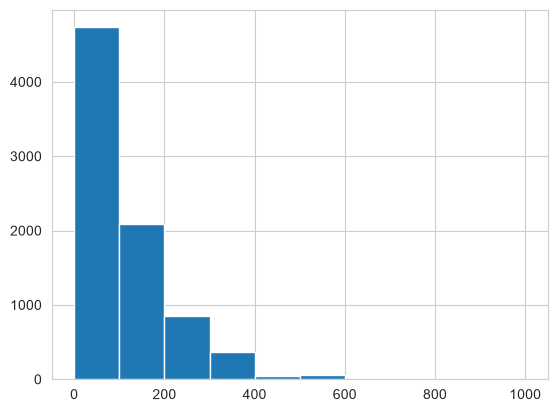

In [4]:
visco['c_surfactant1'].hist()
sum(visco['c_surfactant1'] == 0)

5444

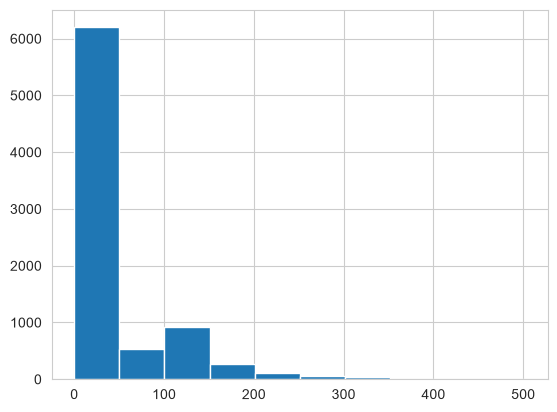

In [5]:
visco['c_surfactant2'].hist()
sum(visco['c_surfactant2'] == 0)

2653

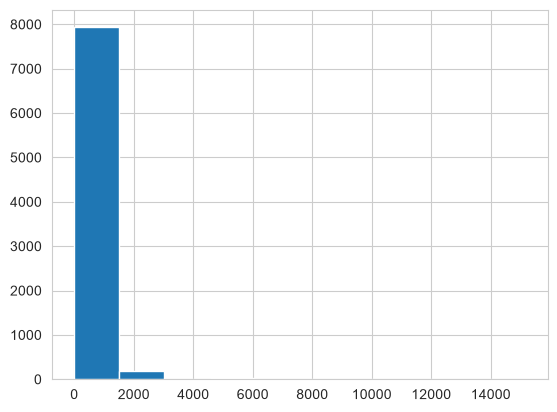

In [6]:
visco['c_additive1'].hist()
sum(visco['c_additive1'] == 0)

6858

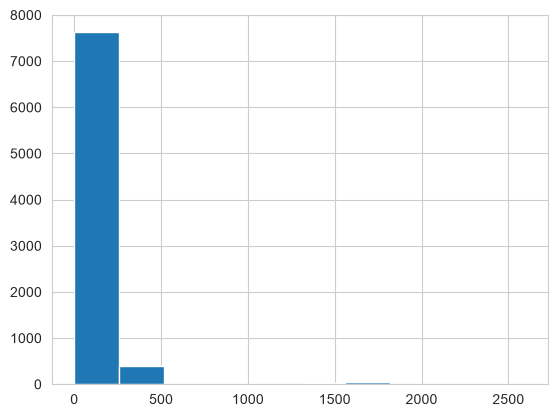

In [7]:
visco['c_additive2'].hist()
sum(visco['c_additive2'] == 0)

In [8]:
visco[['c_surfactant1', 'c_surfactant2', 'c_additive1', 'c_additive2']] \
    = visco.apply(
    lambda row: calculate_concentration(row['c_surfactant1'], row['c_surfactant2'], row['c_additive1'], row['c_additive2']),
    axis=1,
    result_type='expand'
)

<Axes: >

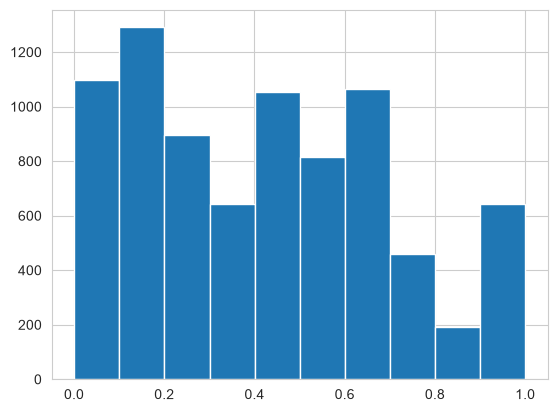

In [9]:
visco['c_surfactant1'].hist()

<Axes: >

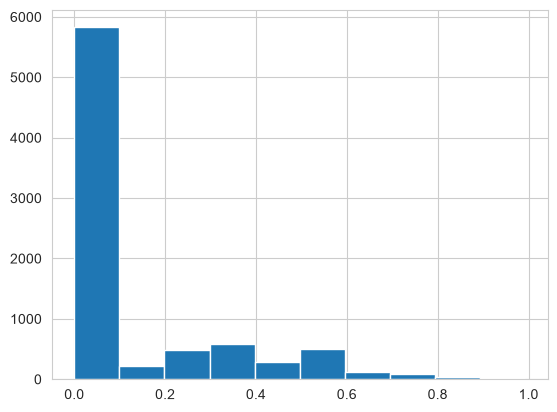

In [10]:
visco['c_surfactant2'].hist()

<Axes: >

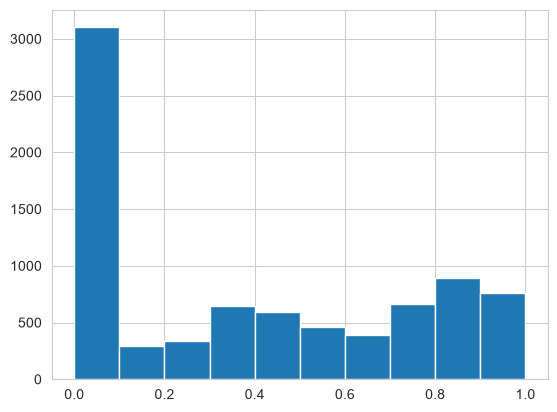

In [11]:
visco['c_additive1'].hist()

<Axes: >

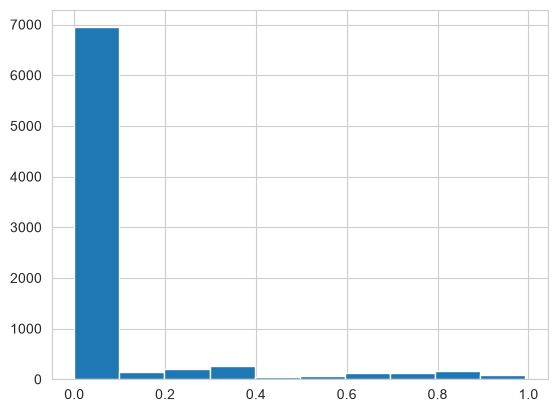

In [12]:
visco['c_additive2'].hist()

<Axes: xlabel='viscoelasticity', ylabel='c_surfactant1'>

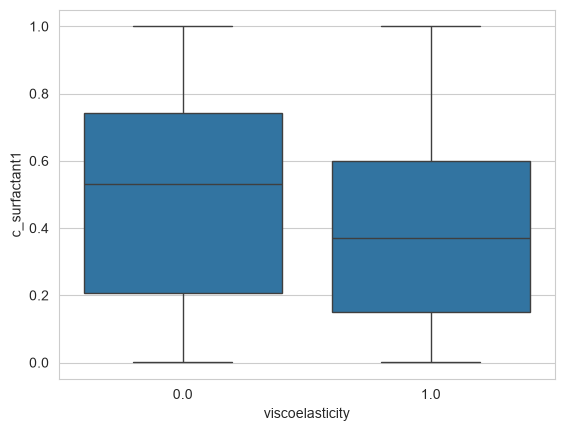

In [13]:
sns.boxplot(visco, x="viscoelasticity", y="c_surfactant1")

<Axes: xlabel='viscoelasticity', ylabel='c_surfactant2'>

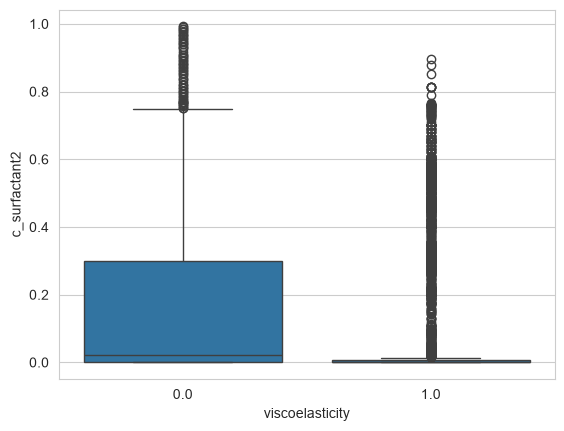

In [14]:
sns.boxplot(visco, x="viscoelasticity", y="c_surfactant2")

<Axes: xlabel='viscoelasticity', ylabel='c_additive1'>

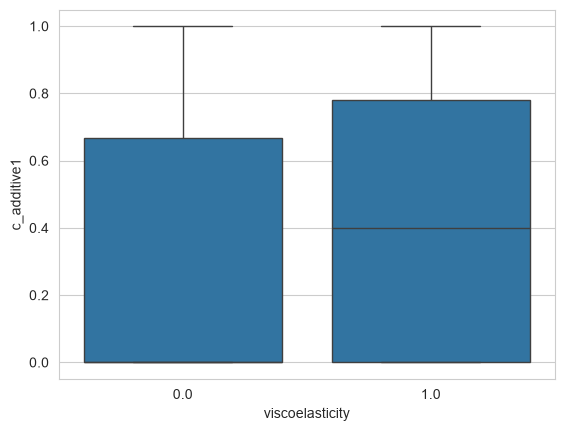

In [15]:
sns.boxplot(visco, x="viscoelasticity", y="c_additive1")

<Axes: xlabel='viscoelasticity', ylabel='c_additive2'>

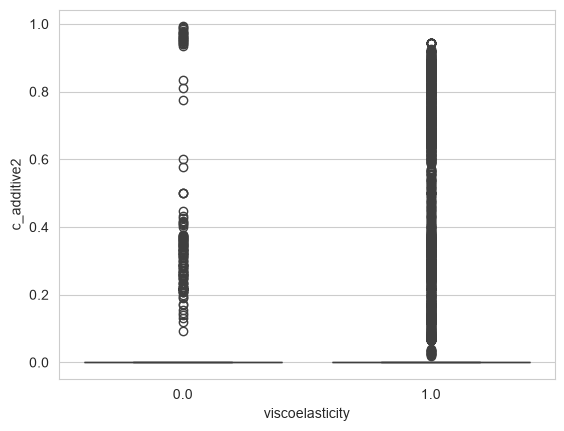

In [16]:
sns.boxplot(visco, x="viscoelasticity", y="c_additive2")

In [17]:
visco['surf_ratio'] = visco['c_surfactant1']/visco['c_surfactant2']

<Axes: >

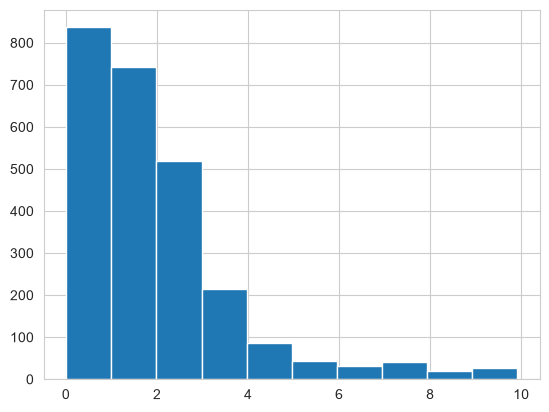

In [18]:
visco[visco['surf_ratio'] < 10]['surf_ratio'].hist()

<Axes: >

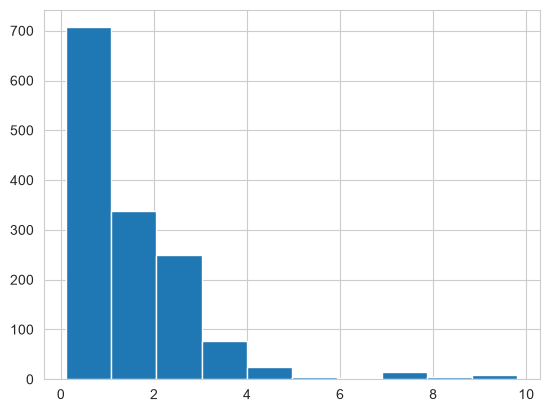

In [19]:
visco[(visco['viscoelasticity'] == 1) & (visco['surf_ratio'] < 10)]['surf_ratio'].hist()

<Axes: >

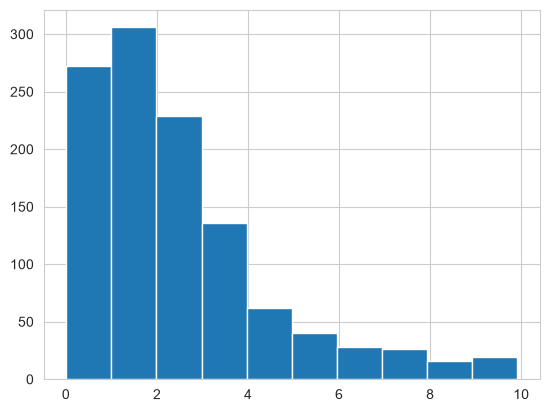

In [20]:
visco[(visco['viscoelasticity'] == 0) & (visco['surf_ratio'] < 10)]['surf_ratio'].hist()

<Axes: xlabel='viscoelasticity', ylabel='surf_ratio'>

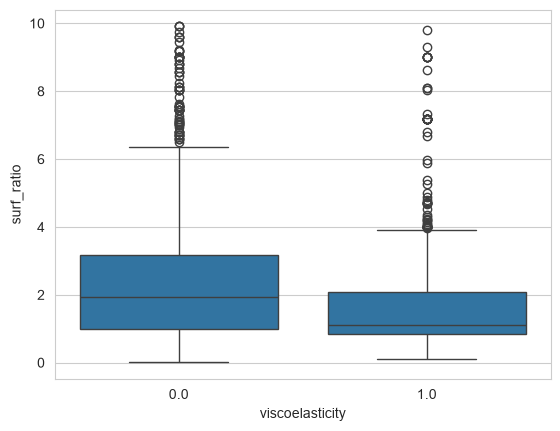

In [21]:
sns.boxplot(visco[visco['surf_ratio'] < 10], x="viscoelasticity", y="surf_ratio")

In [22]:
len(visco[(visco['viscoelasticity'] == 0) & (visco['c_surfactant2'] == 0)])

1075

In [23]:
len(visco[(visco['viscoelasticity'] == 0) & (visco['c_surfactant2'] != 0)])

1245

In [24]:
len(visco[(visco['viscoelasticity'] == 0) & (visco['c_additive1'] == 0)])

1173

In [25]:
len(visco[(visco['viscoelasticity'] == 0) & (visco['c_additive1'] != 0)])

1147

In [26]:
def grouping(s1, s2, a1, a2):
    return f'{int(s1 != 0)}{int(s2 != 0)}{int(a1 != 0)}{int(a2 != 0)}'
grouping(0,0,1,1)

'0011'

In [27]:
visco['group'] = visco.apply(
    lambda row: grouping(row['c_surfactant1'],row['c_surfactant2'],row['c_additive1'],row['c_additive2']),
    axis=1
)

In [28]:
counts = visco['group'].value_counts()
counts

group
1010    3783
1100    2123
1011    1131
1000     519
1110     433
1111     152
1001      11
Name: count, dtype: int64

In [32]:
c = counts.to_dict()
c

{'1010': 3783,
 '1100': 2123,
 '1011': 1131,
 '1000': 519,
 '1110': 433,
 '1111': 152,
 '1001': 11}

In [41]:
import pandas as pd
import plotly.express as px

plot_df = counts.rename_axis("group").reset_index(name="count")
plot_df["group"] = plot_df["group"].astype(str)

fig = px.treemap(
    plot_df,
    path=["group"],
    values="count",
    title="Distribution of categories",
)

fig.show()